Code for Analysis 2: 

--> GSEA Work

In [ ]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

%matplotlib inline

# ---- configuration ----------------------------------------------------------
INPUT_DIR = Path("inputs")             # written by 00_preprocess.ipynb
REGULON_FILES = {                      # name -> path (.gmt, or CSV with columns tf,target); leave empty to skip
     "TF Link":   "../data/TFLink_Caenorhabditis_elegans_interactions_All_GMT_proteinName_v1.0.gmt",
    }
SEED = 0
TYPES = ["sensory", "interneuron", "motor", "pharyngeal"]
OUT = Path("../figures/analysis_2")  # output directory
GSEA_PERM = 500     # gene-set permutations
FDR = 0.05
TOPN = 5
OUT.mkdir(exist_ok=True)

In [12]:
# Helper Functions
def cpm(counts):
    return counts / counts.sum(axis=0) * 1e6


def one_vs_all_log2fc(counts, pseudo=1.0):
    """log2 fold change of each column (CPM) vs the mean of all other columns."""
    c = cpm(counts)
    n = c.shape[1]
    rest = (c.sum(axis=1).values[:, None] - c.values) / (n - 1)
    return pd.DataFrame(np.log2((c.values + pseudo) / (rest + pseudo)),
                        index=c.index, columns=c.columns)


def read_gene_sets(path):
    p, sets = Path(path), {}
    if p.suffix.lower() == ".gmt":
        for line in open(p):
            f = line.rstrip("\n").split("\t")
            if len(f) >= 3:
                sets[f[0]] = {g for g in f[2:] if g}
    else:
        df = pd.read_csv(p)
        tf, tg = df.columns[:2]
        for name, sub in df.groupby(tf):
            sets[str(name)] = set(sub[tg].astype(str)) | {str(name)}
    return sets


def _running_es(mask, w):
    hw = np.where(mask, w, 0.0)
    s = hw.sum()
    n_miss = (~mask).sum()
    if s == 0 or n_miss == 0:
        return 0.0
    dev = np.cumsum(hw) / s - np.cumsum(~mask) / n_miss
    return float(dev[np.argmax(np.abs(dev))])


def _bh(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = np.empty_like(p)
    q[o] = np.minimum.accumulate((p[o] * len(p) / (np.arange(len(p)) + 1))[::-1])[::-1]
    return np.minimum(q, 1.0)


def gsea(metric, sets, n_perm, rng, min_size=5):
    r = metric.sort_values(ascending=False)
    genes, w = r.index.values, np.abs(r.values)
    N = len(genes)
    cache, rows = {}, []
    for name, gs in sets.items():
        mask = np.isin(genes, list(gs))
        k = int(mask.sum())
        if k < min_size or k >= N:
            continue
        es = _running_es(mask, w)
        if k not in cache:
            null = []
            for _ in range(n_perm):
                m = np.zeros(N, bool)
                m[rng.choice(N, k, replace=False)] = True
                null.append(_running_es(m, w))
            cache[k] = np.array(null)
        null = cache[k]
        side = null[null > 0] if es >= 0 else -null[null < 0]
        nes = es / side.mean() if len(side) and side.mean() > 0 else np.nan
        p = (1 + np.sum(np.abs(null) >= abs(es))) / (1 + n_perm)
        rows.append(dict(gene_set=name, size=k, ES=es, NES=nes, p=p))
    df = pd.DataFrame(rows)
    if len(df):
        df["fdr"] = _bh(df.p.values)
    return df


def analysis2(counts, types, lfc, reg_sets, n_perm, out, seed, fdr=0.05, topn=5):
    rng = np.random.default_rng(seed)
    ntype = types.reindex(counts.columns)
    agg = counts.T.groupby(ntype.values).sum().T
    tlfc = one_vs_all_log2fc(agg)                      # genes x types (CPM aggregate)

    # Leave-one-out type profiles: a neuron's own counts are removed from its own type's aggregate before
    # that type (and every other type) is scored against it, so a neuron never helps build the profile
    # it is compared with. Types with a single neuron cannot be left out and keep the full profile.
    n_in_type = ntype.value_counts()
    loo = {}
    for nrn in lfc.columns:
        u = ntype[nrn]
        if n_in_type[u] < 2:
            loo[nrn] = tlfc
            continue
        a = agg.copy()
        a[u] = a[u] - counts[nrn]
        loo[nrn] = one_vs_all_log2fc(a)

    all_enr, summ = [], []
    status = {}                                        # per-type outcome, so skipped types are reported
    for t in tlfc.columns:
        g = gsea(tlfc[t], reg_sets, n_perm, rng)
        if not len(g):
            status[t] = dict(status="no testable gene sets (all below min size)", n_sig_sets=0)
            continue
        g.insert(0, "type", t)
        all_enr.append(g)
        sig = g[g.fdr < fdr]
        if sig.empty:
            status[t] = dict(status=f"no significant gene sets (FDR < {fdr}); best FDR = {g.fdr.min():.3g}",
                             n_sig_sets=0)
            continue
        status[t] = dict(status="analysed", n_sig_sets=len(sig))
        universe = sorted(set().union(*[reg_sets[s] for s in sig.gene_set]) & set(tlfc.index))
        members = types.index[types == t]
        t_vec = tlfc.loc[universe, t]
        t_top = set(t_vec.abs().nlargest(topn).index)
        null_abs = lfc.loc[universe].abs().values.mean()   # average |log2FC| across all neurons
        for nrn in lfc.columns:
            n_vec = lfc.loc[universe, nrn]
            n_top = set(n_vec.abs().nlargest(topn).index)
            row = dict(type=t, neuron=nrn, is_member=nrn in members,
                       n_sig_sets=len(sig), n_genes=len(universe))
            for tag, prof in (("", tlfc[t]), ("_loo", loo[nrn][t])):   # full profile, then leave-one-out
                tv = prof.loc[universe]
                tt = set(tv.abs().nlargest(topn).index)
                row["spearman_vs_type" + tag] = stats.spearmanr(n_vec, tv)[0] if len(universe) > 2 else np.nan
                row["top5_overlap_jaccard" + tag] = len(n_top & tt) / len(n_top | tt)
            row.update(neuron_top5_mean_abs=n_vec.abs().nlargest(topn).mean(),
                       type_top5_mean_abs=t_vec.abs().nlargest(topn).mean(),
                       null_mean_abs=null_abs)
            summ.append(row)
    enr = pd.concat(all_enr) if all_enr else pd.DataFrame()
    enr.to_csv(out / "analysis2_gsea_by_type.csv", index=False)
    sm = pd.DataFrame(summ)
    sm.to_csv(out / "analysis2_neuron_vs_type_enrichment.csv", index=False)

    # summary table with a row for every type x member/non-member, including types with nothing to compare
    metrics = ["spearman_vs_type", "spearman_vs_type_loo", "top5_overlap_jaccard", "top5_overlap_jaccard_loo"]
    full_index = pd.MultiIndex.from_product([list(tlfc.columns), [False, True]], names=["type", "is_member"])
    if len(sm):
        agg_tab = sm.groupby(["type", "is_member"])[metrics].mean().reindex(full_index)
    else:
        agg_tab = pd.DataFrame(np.nan, index=full_index, columns=metrics)
    agg_tab["n_sig_sets"] = [status[t]["n_sig_sets"] for t, _ in agg_tab.index]
    agg_tab["status"] = [status[t]["status"] for t, _ in agg_tab.index]
    agg_tab.to_csv(out / "analysis2_member_vs_nonmember_summary.csv")
    print(agg_tab.round(3).to_string())

    # one-sided Mann-Whitney per type and metric: are members' per-neuron scores higher than non-members'?
    # auc = P(random member scores higher than random non-member); 0.5 = no difference.
    # FDR (Benjamini-Hochberg) is applied across types within each metric.
    rows = []
    for t, d in (sm.groupby("type") if len(sm) else []):
        for m in metrics:
            a, b = d.loc[d.is_member, m].dropna(), d.loc[~d.is_member, m].dropna()
            if len(a) < 2 or len(b) < 2:
                continue
            u, p = stats.mannwhitneyu(a, b, alternative="greater")
            rows.append(dict(type=t, metric=m, n_members=len(a), n_nonmembers=len(b),
                             median_members=a.median(), median_nonmembers=b.median(),
                             auc=u / (len(a) * len(b)), p_greater=p))
    tests = pd.DataFrame(rows)
    if len(tests):
        tests["fdr"] = tests.groupby("metric")["p_greater"].transform(lambda x: _bh(x.values))
    tests.to_csv(out / "analysis2_member_vs_nonmember_tests.csv", index=False)
    if len(tests):
        print(tests.round(4).to_string(index=False))
    return enr, sm

def analysis2_topx(counts, types, lfc, reg_sets, enr, out, Xs=(10, 25, 50, 100, 250), fdr=0.05):
    """Sensitivity of the Analysis 2 Spearman result to the number of genes (X) used.

    For each type with significant regulon sets (from `enr`, the first value analysis2 returns), the gene
    universe is the union of those regulons. For each neuron, the X genes with the largest |log2FC| in the
    type's leave-one-out profile (restricted to the universe) are selected, and the neuron's Spearman
    correlation with that profile is computed over those genes. "all" = the whole universe (the original
    analysis). Because genes are chosen from the type profile, never from the neuron, members and non-members
    are treated identically. Outputs: analysis2_topx_spearman.csv, analysis2_topx_summary.csv and a bar chart.
    """
    colors = {"sensory": "#1b9e77", "interneuron": "#7570b3", "motor": "#d95f02", "pharyngeal": "#e7298a"}
    ntype = types.reindex(counts.columns)
    agg = counts.T.groupby(ntype.values).sum().T
    n_in_type = ntype.value_counts()
    tlfc = one_vs_all_log2fc(agg)
    loo = {}
    for nrn in lfc.columns:
        u = ntype[nrn]
        if n_in_type[u] < 2:
            loo[nrn] = tlfc
            continue
        a = agg.copy()
        a[u] = a[u] - counts[nrn]
        loo[nrn] = one_vs_all_log2fc(a)

    rows, tested, untested = [], [], []
    for t in tlfc.columns:
        sig = enr[(enr.type == t) & (enr.fdr < fdr)] if len(enr) else enr
        if not len(sig):
            untested.append(t)
            continue
        universe = sorted(set().union(*[reg_sets[s] for s in sig.gene_set]) & set(tlfc.index))
        tested.append(t)
        steps = [X for X in Xs if X < len(universe)] + ["all"]
        members = set(types.index[types == t])
        for nrn in lfc.columns:
            prof = loo[nrn][t].loc[universe]
            order = prof.abs().sort_values(ascending=False).index
            n_vec = lfc.loc[universe, nrn]
            for X in steps:
                genes = order if X == "all" else order[:X]
                rho = stats.spearmanr(n_vec.loc[genes], prof.loc[genes])[0] if len(genes) > 2 else np.nan
                rows.append(dict(type=t, X=X, n_genes=len(genes), neuron=nrn,
                                 is_member=nrn in members, spearman=rho))
    df = pd.DataFrame(rows)
    df.to_csv(out / "analysis2_topx_spearman.csv", index=False)
    if df.empty:
        print("No type had significant regulon sets: nothing to plot.")
        return df, pd.DataFrame()

    srows = []
    for (t, X), d in df.groupby(["type", "X"], sort=False):
        a, b = d.loc[d.is_member, "spearman"].dropna(), d.loc[~d.is_member, "spearman"].dropna()
        p = stats.mannwhitneyu(a, b, alternative="greater")[1] if len(a) > 1 and len(b) > 1 else np.nan
        srows.append(dict(type=t, X=X, n_genes=d.n_genes.iloc[0],
                          mean_members=a.mean(), sem_members=a.sem(), mean_nonmembers=b.mean(),
                          sem_nonmembers=b.sem(), n_members=len(a), n_nonmembers=len(b), p_greater=p))
    summ = pd.DataFrame(srows)
    ok = summ.p_greater.notna()
    summ.loc[ok, "fdr"] = _bh(summ.loc[ok, "p_greater"].values)     # BH across all type x X tests
    summ.to_csv(out / "analysis2_topx_summary.csv", index=False)
    print(summ.round(3).to_string(index=False))

    order_t = [t for t in ["sensory", "interneuron", "motor", "pharyngeal"] if t in tlfc.columns]
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
    for ax, t in zip(axes.flatten(), order_t):
        if t in untested:
            ax.text(0.5, 0.5, "no significant regulon sets\n(not testable)", ha="center", va="center",
                    transform=ax.transAxes, color="0.4")
            ax.set_title(t)
            ax.set_xticks([])
            continue
        d = summ[summ.type == t].reset_index(drop=True)
        x = np.arange(len(d))
        w = 0.38
        ax.bar(x - w / 2, d.mean_nonmembers, w, yerr=d.sem_nonmembers, color="0.7", capsize=2, label="non-members")
        ax.bar(x + w / 2, d.mean_members, w, yerr=d.sem_members, color=colors[t], capsize=2, label="members")
        for i, r in d.iterrows():
            if r.get("fdr", np.nan) < 0.05:
                ax.text(i + w / 2, max(r.mean_members, 0) + (r.sem_members if np.isfinite(r.sem_members) else 0) + 0.02,
                        "*", ha="center", fontsize=12)
        ax.axhline(0, color="k", lw=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels([f"{X}" if X == "all" else str(X) for X in d.X])
        ax.set_title(t)
        ax.set_xlabel("X (top genes by |log2FC| in the type profile; all = whole regulon universe)", fontsize=7)
    for ax in axes[:, 0]:
        ax.set_ylabel("mean Spearman (leave-one-out)")
    h, l = axes.flatten()[order_t.index(tested[0])].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False)
    fig.text(0.99, 0.01, "* FDR < 0.05, one-sided Mann-Whitney (members > non-members)", ha="right", fontsize=7)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(out / "analysis2_topx_spearman.png", dpi=200)
    plt.show()
    return df, summ

In [ ]:
# Load Data
meta = pd.read_csv(INPUT_DIR / "neurons.csv")
counts = pd.read_csv(INPUT_DIR / "counts.csv", index_col=0)
meta["neuron"] = meta["neuron"].astype(str)
nodes = [n for n in meta["neuron"] if n in counts.columns]
meta = meta.set_index("neuron").loc[nodes]
types = meta["type"]
counts = counts[nodes]
counts = counts.loc[counts.sum(axis=1) > 0]
print(f"{len(nodes)} neurons, {counts.shape[0]} genes")
print(types.value_counts().to_dict())
lfc = one_vs_all_log2fc(counts)          # genes x neurons, one-vs-all log2FC on CPM

reg_sets = {}
for name, path in REGULON_FILES.items():
    for k, v in read_gene_sets(path).items():
        reg_sets[f"{name}:{k}"] = v
print(f"{len(reg_sets)} gene sets loaded")

126 neurons, 13546 genes
{'interneuron': 45, 'sensory': 39, 'motor': 28, 'pharyngeal': 14}
255 gene sets loaded
{'interneuron': 45, 'sensory': 39, 'motor': 28, 'pharyngeal': 14}


                       spearman_vs_type  spearman_vs_type_loo  top5_overlap_jaccard  top5_overlap_jaccard_loo  n_sig_sets                                                   status
type        is_member                                                                                                                                                             
interneuron False                   NaN                   NaN                   NaN                       NaN           0  no significant gene sets (FDR < 0.05); best FDR = 0.225
            True                    NaN                   NaN                   NaN                       NaN           0  no significant gene sets (FDR < 0.05); best FDR = 0.225
motor       False                   NaN                   NaN                   NaN                       NaN           0  no significant gene sets (FDR < 0.05); best FDR = 0.337
            True                    NaN                   NaN                   NaN                      

,type,gene_set,size,ES,NES,p,fdr
19,pharyngeal,TF Link:snpc-4,2658,0.315601,NaN,0.001996,0.009763
81,pharyngeal,TF Link:ceh-82,2003,0.364986,NaN,0.001996,0.009763
82,pharyngeal,TF Link:tbx-2,1435,0.359327,NaN,0.001996,0.009763
84,pharyngeal,TF Link:mep-1,2102,0.358310,NaN,0.001996,0.009763
85,pharyngeal,TF Link:lin-13,1827,0.322653,NaN,0.001996,0.009763
42,pharyngeal,TF Link:nhr-6,1579,0.374776,NaN,0.001996,0.009763
89,pharyngeal,TF Link:rbr-2,659,0.365564,NaN,0.001996,0.009763
91,pharyngeal,TF Link:efl-1,2619,0.353816,NaN,0.001996,0.009763
92,pharyngeal,TF Link:xbp-1,1088,0.369375,NaN,0.001996,0.009763
118,pharyngeal,TF Link:madf-10,379,0.383682,NaN,0.001996,0.009763


      type   X  n_genes  mean_members  sem_members  mean_nonmembers  sem_nonmembers  n_members  n_nonmembers  p_greater  fdr
pharyngeal  10       10         0.879        0.026            0.728           0.018         14           112        0.0  0.0
pharyngeal  25       25         0.960        0.014            0.836           0.011         14           112        0.0  0.0
pharyngeal  50       50         0.900        0.011            0.696           0.010         14           112        0.0  0.0
pharyngeal 100      100         0.840        0.009            0.611           0.010         14           112        0.0  0.0
pharyngeal 250      250         0.786        0.006            0.560           0.011         14           112        0.0  0.0
pharyngeal all     4666         0.308        0.034            0.053           0.008         14           112        0.0  0.0
   sensory  10       10        -0.124        0.029           -0.240           0.011         39            87        0.0  0.0


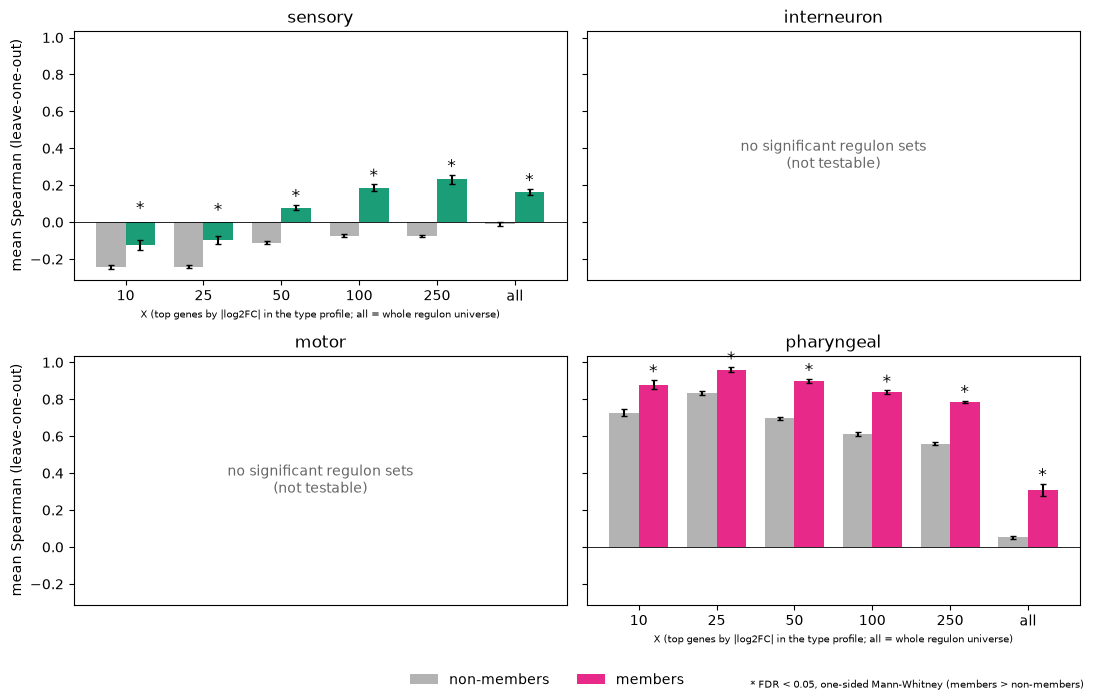

In [13]:
# Run Analysis 2
if reg_sets:
    enr, sm = analysis2(counts, types, lfc, reg_sets, GSEA_PERM, OUT, SEED, fdr=FDR, topn=TOPN)
    display(enr.sort_values("fdr").head(20))
else:
    print("No regulon files configured: set REGULON_FILES in the first cell to run Analysis 2.")

df, summ = analysis2_topx(counts, types, lfc, reg_sets, enr, OUT)

In [1]:
# secondary analysis

def _spearman_fast(x, y):
    """Spearman correlation (rank Pearson); NaN if fewer than 3 points or a constant vector."""
    if len(x) < 3:
        return np.nan
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    rx, ry = rx - rx.mean(), ry - ry.mean()
    d = np.sqrt((rx @ rx) * (ry @ ry))
    return float(rx @ ry / d) if d > 0 else np.nan


def _gap_by_x(pool_idx, prof_by_neuron, lfc_arr, is_member, steps):
    """For one gene pool: {X: (mean Spearman of members, mean Spearman of non-members)}.
    Per neuron, take the X genes with the largest |profile| in the pool, correlate with the neuron."""
    n = lfc_arr.shape[1]
    rho = {X: np.full(n, np.nan) for X in steps}
    for j in range(n):
        prof = prof_by_neuron[j][pool_idx]
        nv = lfc_arr[pool_idx, j]
        order = np.argsort(-np.abs(prof), kind="stable")
        for X in steps:
            idx = order if X == "all" else order[:X]
            rho[X][j] = _spearman_fast(nv[idx], prof[idx])
    return {X: (np.nanmean(rho[X][is_member]), np.nanmean(rho[X][~is_member])) for X in steps}


def analysis2_topx_control(counts, types, lfc, reg_sets, enr, out, Xs=(10, 25, 50, 100, 250),
                           fdr=0.05, n_draws=100, n_bins=20, seed=0):
    """Does the regulon gene pool separate members from non-members MORE than ordinary genes would?

    Same quantity as analysis2_topx (leave-one-out Spearman over the top-X genes of the type profile), reduced to
    one number per type and X: gap = mean(members) - mean(non-members). It is computed for
      * the regulon pool (the union of the type's significant regulons),
      * `n_draws` random gene pools of the same size, with each regulon gene replaced by a non-regulon gene
        from the same mean-expression bin (`n_bins` quantile bins), the matched null,
      * all genes (one reference line).
    Empirical p = (1 + #null gaps >= regulon gap) / (1 + n_draws), one-sided; BH across type x X.
    Outputs: analysis2_topx_control.csv and analysis2_topx_control.png.
    """
    colors = {"Sensory": "#1b9e77", "Interneuron": "#7570b3", "Motor": "#d95f02", "Pharyngeal": "#e7298a"}
    rng = np.random.default_rng(seed)
    ntype = types.reindex(counts.columns)
    agg = counts.T.groupby(ntype.values).sum().T
    n_in_type = ntype.value_counts()
    tlfc = one_vs_all_log2fc(agg)
    genes = np.array(tlfc.index)
    gpos = {g_: i for i, g_ in enumerate(genes)}
    lfc_arr = lfc.reindex(genes).values                      # genes x neurons
    neurons = list(lfc.columns)
    loo = {}
    for nrn in neurons:
        u = ntype[nrn]
        if n_in_type[u] < 2:
            loo[nrn] = tlfc
            continue
        a = agg.copy()
        a[u] = a[u] - counts[nrn]
        loo[nrn] = one_vs_all_log2fc(a)

    # expression bins for matched sampling (mean log2 CPM across neurons)
    expr = np.log2(cpm(counts).reindex(genes).mean(axis=1).values + 1.0)
    bins = np.digitize(expr, np.quantile(expr, np.linspace(0, 1, n_bins + 1)[1:-1]))
    members_by_bin = {b: np.where(bins == b)[0] for b in np.unique(bins)}

    rows, tested, untested = [], [], []
    for t in tlfc.columns:
        sig = enr[(enr.type == t) & (enr.fdr < fdr)] if len(enr) else enr
        if not len(sig):
            untested.append(t)
            continue
        tested.append(t)
        universe = sorted(set().union(*[reg_sets[s] for s in sig.gene_set]) & set(gpos))
        reg_idx = np.array([gpos[g_] for g_ in universe])
        steps = [X for X in Xs if X < len(reg_idx)] + ["all"]
        is_member = np.array([ntype[n_] == t for n_ in neurons])
        prof_by_neuron = [loo[n_][t].reindex(genes).values for n_ in neurons]

        reg = _gap_by_x(reg_idx, prof_by_neuron, lfc_arr, is_member, steps)
        allg = _gap_by_x(np.arange(len(genes)), prof_by_neuron, lfc_arr, is_member, steps)

        # matched null pools: same size, same expression-bin composition, excluding the regulon genes
        in_reg = np.zeros(len(genes), bool)
        in_reg[reg_idx] = True
        need = pd.Series(bins[reg_idx]).value_counts()
        null_gap = {X: [] for X in steps}
        for _ in range(n_draws):
            pool = []
            for b, k in need.items():
                cand = members_by_bin[b][~in_reg[members_by_bin[b]]]
                if len(cand) == 0:
                    cand = members_by_bin[b]
                pool.append(rng.choice(cand, size=k, replace=len(cand) < k))
            res = _gap_by_x(np.concatenate(pool), prof_by_neuron, lfc_arr, is_member, steps)
            for X in steps:
                null_gap[X].append(res[X][0] - res[X][1])
        for X in steps:
            g_reg = reg[X][0] - reg[X][1]
            nl = np.array(null_gap[X])
            rows.append(dict(type=t, X=X, n_pool=len(reg_idx), gap_regulon=g_reg,
                             members_regulon=reg[X][0], nonmembers_regulon=reg[X][1],
                             gap_all_genes=allg[X][0] - allg[X][1],
                             null_median=np.nanmedian(nl), null_lo=np.nanpercentile(nl, 2.5),
                             null_hi=np.nanpercentile(nl, 97.5),
                             p_empirical=(1 + np.sum(nl >= g_reg)) / (1 + len(nl))))
        print(f"  control: {t} done ({len(reg_idx)} regulon genes, {n_draws} matched draws)")
    df = pd.DataFrame(rows)
    if df.empty:
        print("No type had significant regulon sets: nothing to plot.")
        return df
    df["fdr"] = _bh(df.p_empirical.values)
    df.to_csv(out / "analysis2_topx_control.csv", index=False)
    print(df.round(3).to_string(index=False))

    order_t = [t for t in ["Sensory", "Interneuron", "Motor", "pharyngeal"] if t in tlfc.columns]
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
    for ax, t in zip(axes.flatten(), order_t):
        if t in untested:
            ax.text(0.5, 0.5, "no significant regulon sets\n(not testable)", ha="center", va="center",
                    transform=ax.transAxes, color="0.4")
            ax.set_title(t)
            ax.set_xticks([])
            continue
        d = df[df.type == t].reset_index(drop=True)
        x = np.arange(len(d))
        ax.fill_between(x, d.null_lo, d.null_hi, color="0.8", label="matched random gene sets (95% interval)")
        ax.plot(x, d.null_median, color="0.45", lw=1, label="matched random gene sets (median)")
        ax.plot(x, d.gap_all_genes, color="k", ls="--", marker="s", ms=4, lw=1, label="all genes")
        ax.plot(x, d.gap_regulon, color=colors[t], marker="o", lw=2, label="regulon genes")
        for i, r in d.iterrows():
            if r.fdr < 0.05:
                ax.text(i, r.gap_regulon + 0.02, "*", ha="center", fontsize=13)
        ax.axhline(0, color="k", lw=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels([str(X) for X in d.X])
        ax.set_title(t)
        ax.set_xlabel("X (top genes by |log2FC| in the type profile; all = whole pool)", fontsize=7)
    fig.supylabel("member - non-member Spearman gap (leave-one-out)", fontsize=9)
    h, l = axes.flatten()[order_t.index(tested[0])].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", bbox_to_anchor=(0.5, 0.025), ncol=4, frameon=False, fontsize=8)
    fig.text(0.5, 0.005, "* FDR < 0.05: regulon gap exceeds expression-matched random gene sets",
             ha="center", fontsize=7)
    fig.tight_layout(rect=(0.02, 0.08, 1, 1))
    fig.savefig(out / "analysis2_topx_control.png", dpi=200)
    plt.show()
    return df

  control: pharyngeal done (4666 regulon genes, 200 matched draws)
  control: sensory done (4924 regulon genes, 200 matched draws)
      type   X  n_pool  gap_regulon  members_regulon  nonmembers_regulon  gap_all_genes  null_median  null_lo  null_hi  p_empirical   fdr
pharyngeal  10    4666        0.151            0.879               0.728          0.357        0.348    0.045    0.604        0.871 1.000
pharyngeal  25    4666        0.125            0.960               0.836          0.248        0.262    0.079    0.417        0.940 1.000
pharyngeal  50    4666        0.204            0.900               0.696          0.219        0.219    0.107    0.325        0.632 1.000
pharyngeal 100    4666        0.228            0.840               0.611          0.181        0.185    0.113    0.261        0.134 0.370
pharyngeal 250    4666        0.226            0.786               0.560          0.194        0.170    0.125    0.216        0.030 0.119
pharyngeal all    4666        0.255      

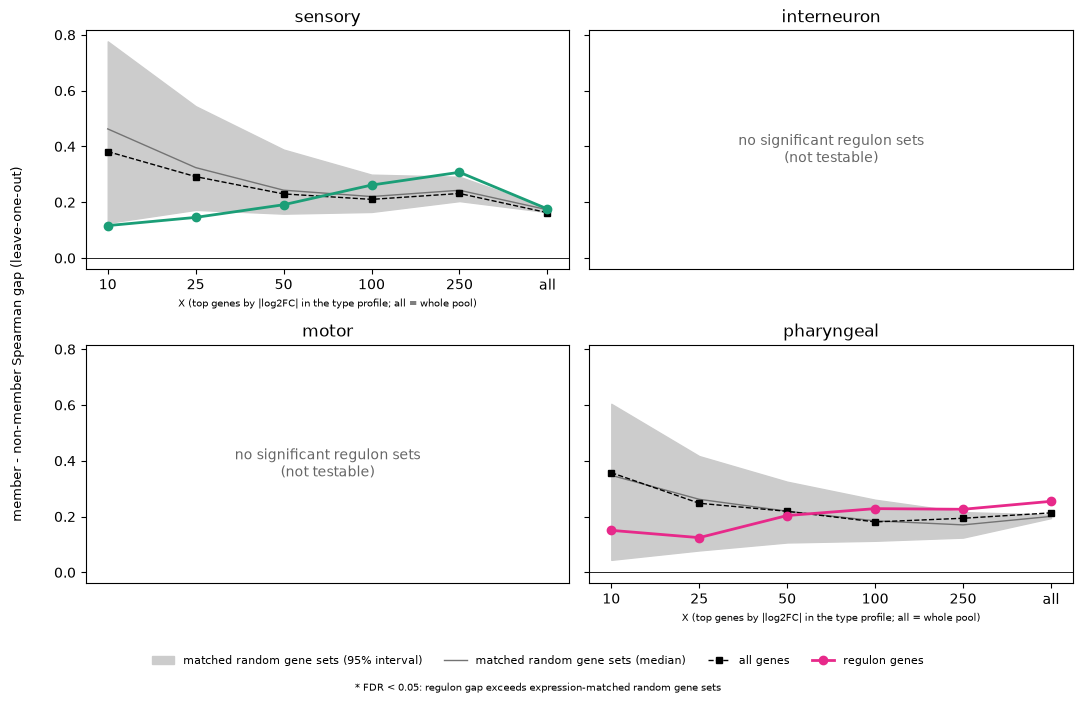

In [15]:
ctrl = analysis2_topx_control(counts, types, lfc, reg_sets, enr, OUT, n_draws=200)